In [145]:
import pandas as pd

**PART B DATA ACQUITION**

# load csv file


In [146]:
df_cd_fd=pd.read_csv('/content/01_demographics_financial.csv')
df_cd_fd

,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount
0,CR00001,20.0,Male,East,Post-Graduate,Salaried,903961.93,983053.14
1,CR00002,36.0,Female,West,Graduate,NaN,657414.02,873074.75
2,CR00003,31.0,Male,West,Secondary,Self-Employed,1278861.13,802401.14
3,CR00004,39.0,Female,North,Secondary,Self-Employed,334219.49,161980.50
4,CR00005,41.0,Female,West,Graduate,Salaried,1157196.59,202750.14
...,...,...,...,...,...,...,...,...
995,CR00996,24.0,Male,East,Secondary,Self-Employed,663683.00,283206.80
996,CR00997,48.0,Male,East,Post-Graduate,Salaried,333600.17,506832.71
997,CR00998,35.0,NaN,East,Graduate,Salaried,1526659.23,230031.70
998,CR00999,20.0,Male,West,Graduate,Self-Employed,1472954.07,153611.31


# load json file

In [147]:
df_cbd=pd.read_json('/content/02_credit_behavior.json')
df_cbd

,customer_id,loan_purpose,credit_score,repayment_history,transaction_count
0,CR00001,Business,708.1,1,40
1,CR00002,Car,636.9,3,41
2,CR00003,Home,651.7,2,55
3,CR00004,Car,664.4,3,25
4,CR00005,Other,611.2,0,50
...,...,...,...,...,...
995,CR00996,Business,726.6,2,41
996,CR00997,Home,596.3,2,41
997,CR00998,Car,634.6,1,37
998,CR00999,Home,621.1,2,48


# load sql file

In [148]:
import sqlite3

conn = sqlite3.connect('/content/03_customer_target.sqlitedb')
tables_df = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print(tables_df)




              name
0  customer_target


# fetch api

In [149]:

file_path = '/content/04_mock_api_response.json'

raw_df = pd.read_json(file_path)

df_api = pd.json_normalize(raw_df['records'])

print(df_api.head())

  customer_id  spending_ratio   join_date
0     CR00001           33.09  2016-09-01
1     CR00002           39.21  2024-08-26
2     CR00003           46.58  2021-02-25
3     CR00004           15.33  2020-04-09
4     CR00005           53.86  2017-01-29


**PART C DATA UNDERSTANDING AND CLEANING**

# INFO AND DESCRIBE DATASET

In [150]:
df_cd_fd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_id      1000 non-null   object 
 1   age              950 non-null    float64
 2   gender           960 non-null    object 
 3   region           1000 non-null   object 
 4   education_level  1000 non-null   object 
 5   employment_type  940 non-null    object 
 6   annual_income    920 non-null    float64
 7   loan_amount      960 non-null    float64
dtypes: float64(3), object(5)
memory usage: 62.6+ KB


In [151]:
df_cbd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        1000 non-null   object 
 1   loan_purpose       1000 non-null   object 
 2   credit_score       930 non-null    float64
 3   repayment_history  1000 non-null   int64  
 4   transaction_count  1000 non-null   int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 39.2+ KB


In [152]:
df_ct.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   customer_id   1000 non-null   object
 1   default_flag  1000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 15.8+ KB


In [153]:
df_api.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     1000 non-null   object 
 1   spending_ratio  950 non-null    float64
 2   join_date       1000 non-null   object 
dtypes: float64(1), object(2)
memory usage: 23.6+ KB


In [154]:
df_cd_fd.describe()

,age,annual_income,loan_amount
count,950.000000,9.200000e+02,9.600000e+02
mean,38.958947,8.430562e+05,4.661195e+05
std,11.195334,5.399546e+05,3.132801e+05
min,18.000000,1.462935e+05,7.254361e+04
25%,31.000000,5.272449e+05,2.620855e+05
50%,39.000000,7.469049e+05,3.872388e+05
75%,46.000000,1.014762e+06,5.738272e+05
max,73.000000,7.059873e+06,3.218376e+06


In [155]:
df_cbd.describe()

,credit_score,repayment_history,transaction_count
count,930.000000,1000.000000,1000.000000
mean,676.881720,1.290000,43.397000
std,63.933467,1.394936,14.890235
min,265.000000,0.000000,25.000000
25%,636.900000,0.000000,37.000000
50%,676.800000,1.000000,42.000000
75%,717.975000,2.000000,46.000000
max,890.000000,12.000000,209.000000


In [156]:
df_ct.describe()

,default_flag
count,1000.000000
mean,0.364000
std,0.481389
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [157]:
df_api.describe()

,spending_ratio
count,950.000000
mean,35.222263
std,25.374823
min,1.000000
25%,17.045000
50%,29.595000
75%,47.195000
max,170.000000


# perform pandas profiling to generate a dataset quality report

In [158]:
print("Dataset Shape:", df_cd_fd.shape)
print("Dataset Shape:", df_cbd.shape)
print("Dataset Shape:", df_ct.shape)
print("Dataset Shape:", df_api.shape)

Dataset Shape: (1000, 8)
Dataset Shape: (1000, 5)
Dataset Shape: (1000, 2)
Dataset Shape: (1000, 3)


In [159]:
%pip install ydata-profiling
from ydata_profiling import ProfileReport

profile = ProfileReport(
    df_cd_fd,
    title="Credit Risk Dataset Quality Report",
    explorative=True
)

profile.to_file("credit_risk_quality_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 8/8 [00:00<00:00, 24.48it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [160]:
profile.to_notebook_iframe()

# check null values

In [161]:
df_cd_fd.isnull().sum()


,0
customer_id,0
age,50
gender,40
region,0
education_level,0
employment_type,60
annual_income,80
loan_amount,40


In [162]:
df_cbd.isnull().sum()

,0
customer_id,0
loan_purpose,0
credit_score,70
repayment_history,0
transaction_count,0


In [163]:
df_ct.isnull().sum()

,0
customer_id,0
default_flag,0


In [164]:
df_api.isnull().sum()

,0
customer_id,0
spending_ratio,50
join_date,0


# handles missing values
simple imputer mean median

In [165]:
from sklearn.impute import SimpleImputer
print("before imputation")
print(df_cd_fd.isnull().sum())

imputer = SimpleImputer(strategy='mean')
df_cd_fd[["age"]] = imputer.fit_transform(df_cd_fd[["age", ]])
print("after imputation")
df_cd_fd.isnull().sum()

before imputation
customer_id         0
age                50
gender             40
region              0
education_level     0
employment_type    60
annual_income      80
loan_amount        40
dtype: int64
after imputation


,0
customer_id,0
age,0
gender,40
region,0
education_level,0
employment_type,60
annual_income,80
loan_amount,40


In [166]:
median_imputer = SimpleImputer(strategy='median')

df_cd_fd[['annual_income']] = median_imputer.fit_transform(
    df_cd_fd[['annual_income']])
df_cd_fd.isnull().sum()

,0
customer_id,0
age,0
gender,40
region,0
education_level,0
employment_type,60
annual_income,0
loan_amount,40


# simple imputer most frequent

In [167]:

print("before imputation")
print(df_cd_fd.isnull().sum())

imputer = SimpleImputer(strategy='most_frequent')
df_cd_fd[["gender"]] = imputer.fit_transform(df_cd_fd[["gender", ]])
print("after imputation")
df_cd_fd.isnull().sum()

before imputation
customer_id         0
age                 0
gender             40
region              0
education_level     0
employment_type    60
annual_income       0
loan_amount        40
dtype: int64
after imputation


,0
customer_id,0
age,0
gender,0
region,0
education_level,0
employment_type,60
annual_income,0
loan_amount,40


# MOST FREQUENT CATEGORY IMPUTATION

In [168]:

print("before imputation")
print(df_cd_fd.isnull().sum())

imputer = SimpleImputer(strategy='most_frequent')
df_cd_fd[["employment_type"]] = imputer.fit_transform(df_cd_fd[["employment_type", ]])
print("after imputation")
df_cd_fd.isnull().sum()

before imputation
customer_id         0
age                 0
gender              0
region              0
education_level     0
employment_type    60
annual_income       0
loan_amount        40
dtype: int64
after imputation


,0
customer_id,0
age,0
gender,0
region,0
education_level,0
employment_type,0
annual_income,0
loan_amount,40


# Missing Indicator + Random Sample Imputation

In [169]:
import numpy as np
from sklearn.impute import MissingIndicator

# Missing Indicator
indicator = MissingIndicator(features="all")
missing_values = indicator.fit_transform(df_cd_fd)

missing_df_cd_fd = pd.DataFrame(
    missing_values,
    columns=[col + "_missing" for col in df_cd_fd.columns],
    index=df_cd_fd.index
)

df_cd_fd = pd.concat([df_cd_fd, missing_df_cd_fd], axis=1)

# Random Sample Imputation
for col in df_cd_fd.columns:
    if not col.endswith("_missing") and df_cd_fd[col].isnull().any():
        missing = df_cd_fd[col].isnull()
        df_cd_fd.loc[missing, col] = np.random.choice(
            df_cd_fd[col].dropna(),
            size=missing.sum(),
            replace=True
        )

# Check Result
print(df_cd_fd.isnull().sum())
print(df_cd_fd.head())

customer_id                0
age                        0
gender                     0
region                     0
education_level            0
employment_type            0
annual_income              0
loan_amount                0
customer_id_missing        0
age_missing                0
gender_missing             0
region_missing             0
education_level_missing    0
employment_type_missing    0
annual_income_missing      0
loan_amount_missing        0
dtype: int64
  customer_id   age  gender region education_level employment_type  \
0     CR00001  20.0    Male   East   Post-Graduate        Salaried   
1     CR00002  36.0  Female   West        Graduate        Salaried   
2     CR00003  31.0    Male   West       Secondary   Self-Employed   
3     CR00004  39.0  Female  North       Secondary   Self-Employed   
4     CR00005  41.0  Female   West        Graduate        Salaried   

   annual_income  loan_amount  customer_id_missing  age_missing  \
0      903961.93    983053.14      

# kni imputor

In [170]:
from sklearn.impute import KNNImputer

num_cols = df_cd_fd.select_dtypes(include="number").columns

# Apply KNN Imputer
imputer = KNNImputer(n_neighbors=5)

df_cd_fd[num_cols] = imputer.fit_transform(df_cd_fd[num_cols])

# Check missing values
print(df_cd_fd.isnull().sum())

# Save cleaned dataset
df_cd_fd.to_csv("demographics_knn_imputed.csv", index=False)


customer_id                0
age                        0
gender                     0
region                     0
education_level            0
employment_type            0
annual_income              0
loan_amount                0
customer_id_missing        0
age_missing                0
gender_missing             0
region_missing             0
education_level_missing    0
employment_type_missing    0
annual_income_missing      0
loan_amount_missing        0
dtype: int64


In [171]:
num_cols = df_api.select_dtypes(include="number").columns

# Apply KNN Imputer
imputer = KNNImputer(n_neighbors=5)

df_api[num_cols] = imputer.fit_transform(df_api[num_cols])

# Check missing values
print(df_api.isnull().sum())

# Save cleaned dataset
df_api.to_csv("knn_imputed_dataset.csv", index=False)

customer_id       0
spending_ratio    0
join_date         0
dtype: int64


# MICE Algorithm

In [172]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

cols = df_cd_fd.select_dtypes(include='number').columns

new2 = df_cd_fd.copy()
print("Before the imputation:\n", new2[cols].isnull().sum())

mice_imputer = IterativeImputer(max_iter=10, random_state=42)
df_mice = new2.copy()

df_mice[cols] = mice_imputer.fit_transform(new2[cols])
print('\nAfter the imputation:\n', df_mice[cols].isnull().sum())

Before the imputation:
 age              0
annual_income    0
loan_amount      0
dtype: int64

After the imputation:
 age              0
annual_income    0
loan_amount      0
dtype: int64


**Outlier** **Handling**

# Detect and treat outliers

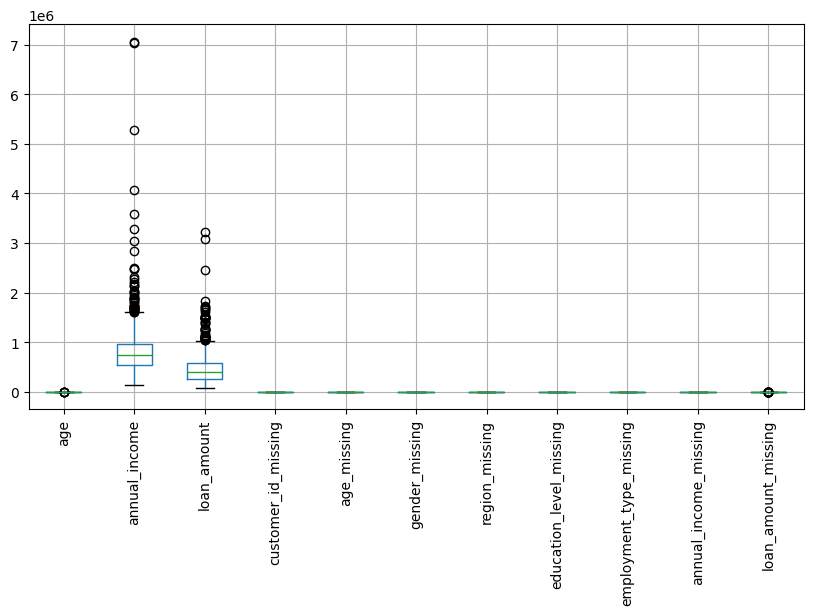

In [173]:
import matplotlib.pyplot as plt
import seaborn as sns

df_cd_fd.boxplot(figsize=(10, 5))
plt.xticks(rotation=90)
plt.show()


# Z-score Method



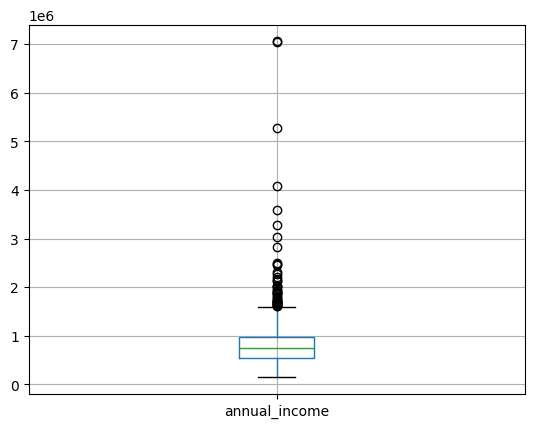

(1000, 16)

In [174]:
df_z=df_cd_fd.copy()
df_z.boxplot(["annual_income"])
plt.show()

df_z.shape

In [175]:
m=df_z["annual_income"].mean()
s=df_z["annual_income"].std()
df_z['annual_income_z']=(df_z["annual_income"]-m)/s
df_z=df_z[df_z['annual_income_z'].abs()<3]

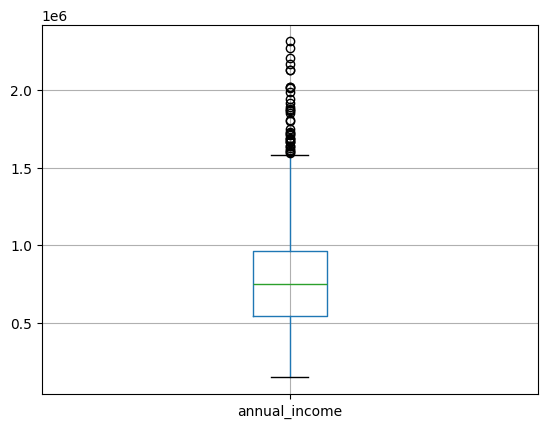

(989, 17)

In [176]:
df_z.boxplot(["annual_income"])
plt.show()
df_z.shape

# IQR Method

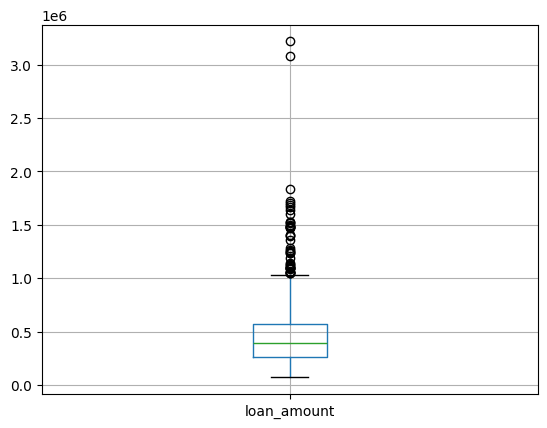

(989, 17)

In [177]:
df_z.boxplot(["loan_amount"])
plt.show()
df_z.shape

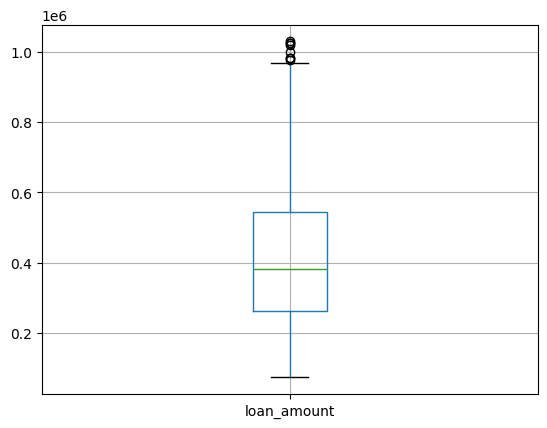

(943, 17)

In [178]:
q1=df_z['loan_amount'].quantile(0.25)
q3=df_z['loan_amount'].quantile(0.75)
iqr=q3-q1
lower=q1-1.5*iqr
upper=q3+1.5*iqr
df_z[(df_z['loan_amount'] > lower) & (df_z['loan_amount'] < upper)]
df_z=df_z[(df_z['loan_amount'] >= lower) & (df_z['loan_amount'] <= upper)]
df_z.boxplot(["loan_amount"])
plt.show()
df_z.shape

# Percentile Method

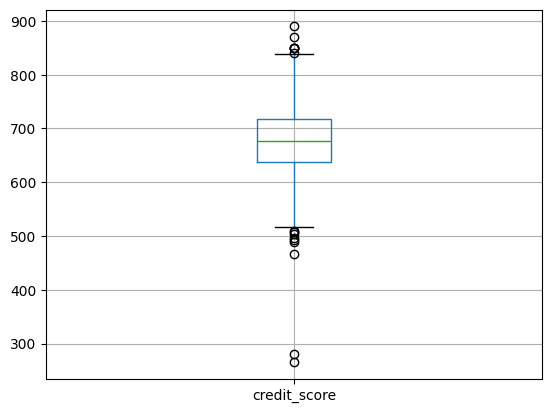

Shape of credit behavior dataset: (1000, 5)


In [179]:
df_cbd.boxplot(["credit_score"])
plt.show()
print("Shape of credit behavior dataset:", df_cbd.shape)

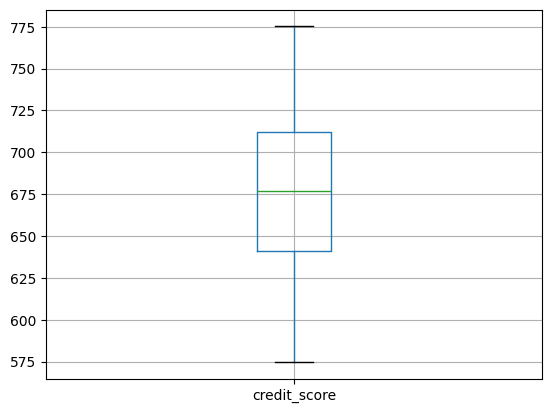

(835, 5)


In [180]:
upp = df_cbd['credit_score'].quantile(0.95)
lowr = df_cbd['credit_score'].quantile(0.05)

df_cbd = df_cbd[(df_cbd['credit_score'] < upp) & (df_cbd['credit_score'] > lowr)]


df_cbd.boxplot(["credit_score"])
plt.show()
print(df_cbd.shape)

**Winsorization** **Technique**

In [181]:
df_cbd = df_cbd.copy()

Q1 = df_cbd['repayment_history'].quantile(0.25)
Q3 = df_cbd['repayment_history'].quantile(0.75)
IQR = Q3 - Q1

l = Q1 - 1.5 * IQR
u = Q3 + 1.5 * IQR


df_cbd.loc[:, 'repayment_history_clip'] = (
    df_cbd['repayment_history'].clip(lower=l, upper=u)
)

# Compare before and after
df_cbd[['repayment_history', 'repayment_history_clip']].describe()

,repayment_history,repayment_history_clip
count,835.000000,835.000000
mean,1.324551,1.267066
std,1.439027,1.153373
min,0.000000,0.000000
25%,0.000000,0.000000
50%,1.000000,1.000000
75%,2.000000,2.000000
max,12.000000,5.000000


**PART E FEATURE ENGINEERING**



In [182]:
df_z.dtypes

,0
customer_id,object
age,float64
gender,object
region,object
education_level,object
employment_type,object
annual_income,float64
loan_amount,float64
customer_id_missing,bool
age_missing,bool


# Date & Time variables → extract Year, Month, Day, Weekday

In [183]:
if 'join_date' in df_z.columns:
    df_z = df_z.drop(columns=['join_date'])

df_z = df_z.merge(df_api[['customer_id', 'join_date']], on='customer_id', how='left')


df_z['join_date'] = pd.to_datetime(df_z['join_date'])
df_z['year'] = df_z['join_date'].dt.year
df_z['month'] = df_z['join_date'].dt.month
df_z['day'] = df_z['join_date'].dt.day
df_z['weekday'] = df_z['join_date'].dt.weekday

print(df_z[['customer_id', 'join_date', 'year', 'month', 'day', 'weekday']].head())
display(df_z.head())

  customer_id  join_date  year  month  day  weekday
0     CR00001 2016-09-01  2016      9    1        3
1     CR00002 2024-08-26  2024      8   26        0
2     CR00003 2021-02-25  2021      2   25        3
3     CR00004 2020-04-09  2020      4    9        3
4     CR00005 2017-01-29  2017      1   29        6


,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount,customer_id_missing,age_missing,...,education_level_missing,employment_type_missing,annual_income_missing,loan_amount_missing,annual_income_z,join_date,year,month,day,weekday
0,CR00001,20.0,Male,East,Post-Graduate,Salaried,903961.93,983053.14,False,False,...,False,False,False,False,0.132290,2016-09-01,2016,9,1,3
1,CR00002,36.0,Female,West,Graduate,Salaried,657414.02,873074.75,False,False,...,False,False,False,False,-0.343175,2024-08-26,2024,8,26,0
2,CR00003,31.0,Male,West,Secondary,Self-Employed,1278861.13,802401.14,False,False,...,False,False,False,False,0.855279,2021-02-25,2021,2,25,3
3,CR00004,39.0,Female,North,Secondary,Self-Employed,334219.49,161980.50,False,False,...,False,False,False,False,-0.966451,2020-04-09,2020,4,9,3
4,CR00005,41.0,Female,West,Graduate,Salaried,1157196.59,202750.14,False,False,...,False,False,False,False,0.620650,2017-01-29,2017,1,29,6


# MIXED VARIABLES NUMERICAL AND CATEGORICAL

In [184]:

from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Identify numerical and categorical columns
numerical_cols = df_cbd.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df_cbd.select_dtypes(include=['object', 'category']).columns

print("Numerical Columns:", list(numerical_cols))
print("Categorical Columns:", list(categorical_cols))
# One-Hot Encoding for categorical variables
df_cbd = pd.get_dummies(
    df_cbd,
    columns=categorical_cols,
    drop_first=True,
    dtype=int)


print(df_cbd.dtypes)


Numerical Columns: ['credit_score', 'repayment_history', 'transaction_count', 'repayment_history_clip']
Categorical Columns: ['customer_id', 'loan_purpose']
credit_score              float64
repayment_history           int64
transaction_count           int64
repayment_history_clip      int64
customer_id_CR00002         int64
                           ...   
customer_id_CR01000         int64
loan_purpose_Car            int64
loan_purpose_Education      int64
loan_purpose_Home           int64
loan_purpose_Other          int64
Length: 842, dtype: object


In [185]:
from sklearn.preprocessing import OrdinalEncoder

# Bin the numerical 'transaction_count' into categories first
df_cbd['transaction_level'] = pd.qcut(
    df_cbd['transaction_count'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

# Now we can apply the OrdinalEncoder on the newly created categorical column
encoder = OrdinalEncoder(
    categories=[['Low', 'Medium', 'High']]
)

df_cbd[['transaction_level_encoded']] = encoder.fit_transform(
    df_cbd[['transaction_level']]
)

print(df_cbd[['transaction_count', 'transaction_level', 'transaction_level_encoded']].head())

   transaction_count transaction_level  transaction_level_encoded
0                 40            Medium                        1.0
1                 41            Medium                        1.0
2                 55              High                        2.0
3                 25               Low                        0.0
4                 50              High                        2.0


# ENCODING CATEGORICAL VARIABLES

# ordinal encoding

In [186]:
education_order = [['Primary', 'Secondary', 'Graduate', 'Post-Graduate']]

oe = OrdinalEncoder(categories=education_order)

df_cd_fd[['education_level']] = oe.fit_transform(df_cd_fd[['education_level']])

# label encoding(binary features)

In [187]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df_cd_fd['gender_lebel'] = le.fit_transform(df_cd_fd['gender'])
df_cd_fd

,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount,customer_id_missing,age_missing,gender_missing,region_missing,education_level_missing,employment_type_missing,annual_income_missing,loan_amount_missing,gender_lebel
0,CR00001,20.0,Male,East,3.0,Salaried,903961.93,983053.14,False,False,False,False,False,False,False,False,1
1,CR00002,36.0,Female,West,2.0,Salaried,657414.02,873074.75,False,False,False,False,False,False,False,False,0
2,CR00003,31.0,Male,West,1.0,Self-Employed,1278861.13,802401.14,False,False,False,False,False,False,False,False,1
3,CR00004,39.0,Female,North,1.0,Self-Employed,334219.49,161980.50,False,False,False,False,False,False,False,False,0
4,CR00005,41.0,Female,West,2.0,Salaried,1157196.59,202750.14,False,False,False,False,False,False,False,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,CR00996,24.0,Male,East,1.0,Self-Employed,663683.00,283206.80,False,False,False,False,False,False,False,False,1
996,CR00997,48.0,Male,East,3.0,Salaried,333600.17,506832.71,False,False,False,False,False,False,False,False,1
997,CR00998,35.0,Male,East,2.0,Salaried,1526659.23,230031.70,False,False,False,False,False,False,False,False,1
998,CR00999,20.0,Male,West,2.0,Self-Employed,1472954.07,153611.31,False,False,False,False,False,False,False,False,1


# one hot encoding(regions ,loan purpose)

In [188]:
if 'region' in df_cd_fd.columns:
    df_cd_fd = pd.get_dummies(
        df_cd_fd,
        columns=['region'],
        drop_first=True,
        dtype=int
    )
else:
    print("'region' column is already encoded or does not exist in the DataFrame.")

In [189]:
if 'loan_purpose' in df_cbd.columns:
     df_cbd = pd.get_dummies(
        df_cbd,
        columns=['loan_purpose'],
        drop_first=True,
        dtype=int)
else:
    print("'loan_purpose' column is already encoded or does not exist in the DataFrame.")

'loan_purpose' column is already encoded or does not exist in the DataFrame.


**encoding numerical features**
Binning (discretive  income into Groups)

In [190]:
df_cd_fd['income_group'] = pd.cut(
    df_cd_fd['annual_income'],
    bins=[0, 1000000, 5000000, 75000000, np.inf],
    labels=['Low', 'Medium', 'High', 'Very High'],
    include_lowest=True
)

df_cd_fd[['annual_income', 'income_group']]

,annual_income,income_group
0,903961.93,Low
1,657414.02,Low
2,1278861.13,Medium
3,334219.49,Low
4,1157196.59,Medium
...,...,...
995,663683.00,Low
996,333600.17,Low
997,1526659.23,Medium
998,1472954.07,Medium


Binarization (Threshold ke Basis par 0 aur 1)

Example: Income > 50,000 hai to 1, warna 0.

In [191]:
df_cd_fd['income_flag'] = (
    df_cd_fd['annual_income'] > 1000000
).astype(int)

df_cd_fd[['annual_income', 'income_flag']]

,annual_income,income_flag
0,903961.93,0
1,657414.02,0
2,1278861.13,1
3,334219.49,0
4,1157196.59,1
...,...,...
995,663683.00,0
996,333600.17,0
997,1526659.23,1
998,1472954.07,1


# Quantile Binning (Equal-Frequency Groups)

In [192]:
df_cd_fd['income_quantile'] = pd.qcut(
    df_cd_fd['annual_income'],
    q=4,
    labels=['Q1', 'Q2', 'Q3', 'Q4'],
    duplicates='drop'
)

df_cd_fd[['annual_income', 'income_quantile']].head()

,annual_income,income_quantile
0,903961.93,Q3
1,657414.02,Q2
2,1278861.13,Q4
3,334219.49,Q1
4,1157196.59,Q4


# K-Means Binning

In [193]:
from sklearn.cluster import KMeans

imputer = SimpleImputer(strategy='median')

income_values = imputer.fit_transform(
    df_cd_fd[['annual_income']]
)

# K-Means clustering
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(income_values)

# Income groups assign karna
df_cd_fd['income_kmeans_group'] = clusters

df_cd_fd[['annual_income', 'income_kmeans_group']]

,annual_income,income_kmeans_group
0,903961.93,3
1,657414.02,1
2,1278861.13,0
3,334219.49,1
4,1157196.59,3
...,...,...
995,663683.00,1
996,333600.17,1
997,1526659.23,0
998,1472954.07,0


**PART F;** **FEATURE SCALING**

# Demographics & Financial

In [194]:
from sklearn.preprocessing import StandardScaler

scaler_df = StandardScaler()

numerical_cols = ['age', 'annual_income', 'loan_amount']

df_cd_fd[[col + '_standardized' for col in numerical_cols]] = (
    scaler_df.fit_transform(df_cd_fd[numerical_cols])
)

df_cd_fd[
    numerical_cols + [col + '_standardized' for col in numerical_cols]
].head()

,age,annual_income,loan_amount,age_standardized,annual_income_standardized,loan_amount_standardized
0,20.0,903961.93,983053.14,-1.738377,0.132356,1.643220
1,36.0,657414.02,873074.75,-0.271311,-0.343346,1.292172
2,31.0,1278861.13,802401.14,-0.729769,0.855707,1.066583
3,39.0,334219.49,161980.50,0.003764,-0.966935,-0.977625
4,41.0,1157196.59,202750.14,0.187148,0.620961,-0.847489


In [195]:
scaler_cb = StandardScaler()

numerical_cols = [
    'credit_score',
    'repayment_history',
    'transaction_count'
]

df_cbd[[col + '_standardized' for col in numerical_cols]] = (
    scaler_cb.fit_transform(df_cbd[numerical_cols])
)

df_cbd[
    numerical_cols + [col + '_standardized' for col in numerical_cols]
].head()

,credit_score,repayment_history,transaction_count,credit_score_standardized,repayment_history_standardized,transaction_count_standardized
0,708.1,1,40,0.657695,-0.225670,-0.232324
1,636.9,3,41,-0.870189,1.164991,-0.170088
2,651.7,2,55,-0.552595,0.469660,0.701220
3,664.4,3,25,-0.280065,1.164991,-1.165868
4,611.2,0,50,-1.421686,-0.921000,0.390039


# normalization

In [196]:
from sklearn.preprocessing import Normalizer
nor = Normalizer()
df_cd_fd[['income_norm','loan_norm']] = nor.fit_transform(df_cd_fd[['annual_income','loan_amount']])

# . Min-Max Scaling

In [197]:
from sklearn.preprocessing import MinMaxScaler

minmaxscal = MinMaxScaler()

df_cd_fd['annual_income_minmax'] = minmaxscal.fit_transform(
    df_cd_fd[['annual_income']]
)


# MAX ABS SCALING

In [198]:
from sklearn.preprocessing import MaxAbsScaler

cols = ['age', 'annual_income', 'loan_amount']

scaler = MaxAbsScaler()

df_cd_fd[[col + '_maxabs' for col in cols]] = (
    scaler.fit_transform(df_cd_fd[cols]))



# ROBUST SCALING

In [199]:
from sklearn.preprocessing import RobustScaler

robust_scaler = RobustScaler()

df_cd_fd['annual_income_robust'] = robust_scaler.fit_transform(
    df_cd_fd[['annual_income']]
)

In [200]:
from sklearn.preprocessing import StandardScaler

api_scaler = StandardScaler()

df_api['spending_ratio_scaled'] = api_scaler.fit_transform(
    df_api[['spending_ratio']]
)

df_api[
    ['spending_ratio', 'spending_ratio_scaled']
].head()

,spending_ratio,spending_ratio_scaled
0,33.09,-0.086259
1,39.21,0.161321
2,46.58,0.459468
3,15.33,-0.804726
4,53.86,0.753975


In [201]:
df_cd_fd.describe()

,age,education_level,annual_income,loan_amount,gender_lebel,region_North,region_South,region_West,income_flag,income_kmeans_group,age_standardized,annual_income_standardized,loan_amount_standardized,income_norm,loan_norm,annual_income_minmax,age_maxabs,annual_income_maxabs,loan_amount_maxabs,annual_income_robust
count,1000.000000,1000.000000,1.000000e+03,1.000000e+03,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03,1.000000e+03,1.000000e+03,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,38.958947,1.707000,8.353641e+05,4.682561e+05,0.680000,0.27600,0.242000,0.230000,0.236000,1.852000,1.909584e-16,-1.865175e-16,5.684342e-17,0.826779,0.487941,0.099669,0.533684,0.118326,0.145495,0.207366
std,10.911575,0.835373,5.185409e+05,3.134422e+05,0.515622,0.44724,0.428509,0.421043,0.424835,1.173658,1.000500e+00,1.000500e+00,1.000500e+00,0.165519,0.225903,0.075003,0.149474,0.073449,0.097391,1.215562
min,18.000000,0.000000,1.462935e+05,7.254361e+04,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,-1.921761e+00,-1.329530e+00,-1.263105e+00,0.144112,0.028827,0.000000,0.246575,0.020722,0.022540,-1.407952
25%,31.000000,1.000000,5.422811e+05,2.638563e+05,0.000000,0.00000,0.000000,0.000000,0.000000,1.000000,-7.297691e-01,-5.654900e-01,-6.524395e-01,0.745471,0.304094,0.057277,0.424658,0.076812,0.081984,-0.479679
50%,38.958947,2.000000,7.469049e+05,3.913739e+05,1.000000,0.00000,0.000000,0.000000,0.000000,1.000000,0.000000e+00,-1.706779e-01,-2.454061e-01,0.884021,0.467447,0.086874,0.533684,0.105796,0.121606,0.000000
75%,46.000000,2.000000,9.688663e+05,5.755994e+05,1.000000,1.00000,0.000000,0.000000,0.000000,3.000000,6.456058e-01,2.575862e-01,3.426374e-01,0.952642,0.666538,0.118979,0.630137,0.137236,0.178848,0.520321
max,73.000000,3.000000,7.059873e+06,3.218376e+06,2.000000,1.00000,1.000000,1.000000,1.000000,3.000000,3.121281e+00,1.200990e+01,8.778319e+00,0.999584,0.989561,1.000000,1.000000,1.000000,1.000000,14.798843


# **PART G:  Feature Construction & Transformation **                                                               Apply transformations                                 FunctionTransformer → log transform, reciprocal, square root  

In [202]:
from sklearn.preprocessing import FunctionTransformer

log_t = FunctionTransformer(np.log1p)
rec_t = FunctionTransformer(np.reciprocal)
sqrt_t = FunctionTransformer(np.sqrt)

df_cd_fd['annual_income_log'] = log_t.fit_transform(df_cd_fd[['annual_income']])
df_cd_fd['annual_income_reciprocal'] = rec_t.fit_transform(df_cd_fd[['annual_income']])
df_cd_fd['annual_income_sqrt'] = sqrt_t.fit_transform(df_cd_fd[['annual_income']])
df_cd_fd.describe()

,age,education_level,annual_income,loan_amount,gender_lebel,region_North,region_South,region_West,income_flag,income_kmeans_group,...,income_norm,loan_norm,annual_income_minmax,age_maxabs,annual_income_maxabs,loan_amount_maxabs,annual_income_robust,annual_income_log,annual_income_reciprocal,annual_income_sqrt
count,1000.000000,1000.000000,1.000000e+03,1.000000e+03,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03,1000.000000
mean,38.958947,1.707000,8.353641e+05,4.682561e+05,0.680000,0.27600,0.242000,0.230000,0.236000,1.852000,...,0.826779,0.487941,0.099669,0.533684,0.118326,0.145495,0.207366,13.512207,1.517975e-06,885.129073
std,10.911575,0.835373,5.185409e+05,3.134422e+05,0.515622,0.44724,0.428509,0.421043,0.424835,1.173658,...,0.165519,0.225903,0.075003,0.149474,0.073449,0.097391,1.215562,0.481415,7.743389e-07,227.953062
min,18.000000,0.000000,1.462935e+05,7.254361e+04,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,...,0.144112,0.028827,0.000000,0.246575,0.020722,0.022540,-1.407952,11.893377,1.416456e-07,382.483268
25%,31.000000,1.000000,5.422811e+05,2.638563e+05,0.000000,0.00000,0.000000,0.000000,0.000000,1.000000,...,0.745471,0.304094,0.057277,0.424658,0.076812,0.081984,-0.479679,13.203542,1.032135e-06,736.397353
50%,38.958947,2.000000,7.469049e+05,3.913739e+05,1.000000,0.00000,0.000000,0.000000,0.000000,1.000000,...,0.884021,0.467447,0.086874,0.533684,0.105796,0.121606,0.000000,13.523694,1.338859e-06,864.236600
75%,46.000000,2.000000,9.688663e+05,5.755994e+05,1.000000,1.00000,0.000000,0.000000,0.000000,3.000000,...,0.952642,0.666538,0.118979,0.630137,0.137236,0.178848,0.520321,13.783882,1.844062e-06,984.309915
max,73.000000,3.000000,7.059873e+06,3.218376e+06,2.000000,1.00000,1.000000,1.000000,1.000000,3.000000,...,0.999584,0.989561,1.000000,1.000000,1.000000,1.000000,14.798843,15.769938,6.835576e-06,2657.042130


# PowerTransformer → Box-Cox and Yeo-Johnson.

In [203]:
from sklearn.preprocessing import PowerTransformer

boxcox = PowerTransformer(method='box-cox')
df_cd_fd['income_boxcox'] = boxcox.fit_transform(
    df_cd_fd[['annual_income']]
)


yeojohnson = PowerTransformer(method='yeo-johnson')
df_cd_fd['income_yeojohnson'] = yeojohnson.fit_transform(
    df_cd_fd[['annual_income']]
)

In [204]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_cols = ['age', 'annual_income', 'loan_amount']
categorical_cols = ['gender']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)

df_processed = preprocessor.fit_transform(df_cd_fd)

In [205]:
feature_names = preprocessor.get_feature_names_out()
df_processed_final = pd.DataFrame(df_processed, columns=feature_names)
df_processed_final

,num__age,num__annual_income,num__loan_amount,cat__gender_Female,cat__gender_Male,cat__gender_Other,remainder__customer_id,remainder__education_level,remainder__employment_type,remainder__customer_id_missing,...,remainder__annual_income_minmax,remainder__age_maxabs,remainder__annual_income_maxabs,remainder__loan_amount_maxabs,remainder__annual_income_robust,remainder__annual_income_log,remainder__annual_income_reciprocal,remainder__annual_income_sqrt,remainder__income_boxcox,remainder__income_yeojohnson
0,-1.738377,0.132356,1.64322,0.0,1.0,0.0,CR00001,3.0,Salaried,False,...,0.109591,0.273973,0.128042,0.30545,0.368173,13.714544,0.000001,950.769125,0.44152,0.44152
1,-0.271311,-0.343346,1.292172,1.0,0.0,0.0,CR00002,2.0,Salaried,False,...,0.07393,0.493151,0.09312,0.271278,-0.209784,13.396071,0.000002,810.810718,-0.219162,-0.219162
2,-0.729769,0.855707,1.066583,0.0,1.0,0.0,CR00003,1.0,Self-Employed,False,...,0.163818,0.424658,0.181145,0.249319,1.24701,14.061481,0.000001,1130.867424,1.137548,1.137548
3,0.003764,-0.966935,-0.977625,1.0,0.0,0.0,CR00004,1.0,Self-Employed,False,...,0.027182,0.534247,0.047341,0.05033,-0.967416,12.719556,0.000003,578.117194,-1.69493,-1.69493
4,0.187148,0.620961,-0.847489,1.0,0.0,0.0,CR00005,2.0,Salaried,False,...,0.14622,0.561644,0.163912,0.062998,0.961805,13.961512,0.000001,1075.730724,0.939476,0.939476
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,-1.371611,-0.331251,-0.590673,0.0,1.0,0.0,CR00996,1.0,Self-Employed,False,...,0.074837,0.328767,0.094008,0.087997,-0.195089,13.405561,0.000002,814.667417,-0.199166,-0.199166
996,0.828989,-0.96813,0.123136,0.0,1.0,0.0,CR00997,3.0,Salaried,False,...,0.027093,0.657534,0.047253,0.157481,-0.968868,12.717701,0.000003,577.58131,-1.699116,-1.699116
997,-0.363002,1.333822,-0.760407,0.0,1.0,0.0,CR00998,2.0,Salaried,False,...,0.19966,0.479452,0.216245,0.071474,1.827898,14.238593,0.000001,1235.580523,1.483605,1.483606
998,-1.738377,1.2302,-1.004339,0.0,1.0,0.0,CR00999,2.0,Self-Employed,False,...,0.191892,0.273973,0.208637,0.047729,1.702003,14.202781,0.000001,1213.653192,1.41413,1.41413



Construct new features



Debt-to-Income ratio                                           Average monthly transactions                                 Spending-to-Income ratio  


In [206]:
# debt to income
df_cd_fd['debt_to_income_ratio'] = (
    df_cd_fd['loan_amount'] / df_cd_fd['annual_income'].replace(0, np.nan)
)
# avearge monthly transactions
df_cbd['avg_monthly_transactions'] = df_cbd['transaction_count'] / 12
#spending to income ratio
df_api['spending_to_income_ratio'] = (
    df_api['spending_ratio']
)

In [208]:
df_final_dataset = pd.read_excel('/content/cleaned_transformed_datasets (1).xlsx')
df_final_dataset

,customer_id,age,gender,education_level,employment_type,annual_income,loan_amount,customer_id_missing,age_missing,gender_missing,...,annual_income_robust,annual_income_log,annual_income_reciprocal,annual_income_sqrt,spending_log,spending_reciprocal,spending_sqrt,income_boxcox,income_yeojohnson,debt_to_income_ratio
0,CR00001,20.0,Male,3,Salaried,903961.93,983053.14,False,False,False,...,0.301744,13.714544,1.106241e-06,950.769125,13.714544,1.106241e-06,950.769125,0.409630,0.409630,1.087494
1,CR00002,36.0,Female,2,Salaried,657414.02,873074.75,False,False,False,...,-0.207683,13.396071,1.521111e-06,810.810718,13.396071,1.521111e-06,810.810718,-0.224078,-0.224078,1.328044
2,CR00003,31.0,Male,1,Self-Employed,1278861.13,802401.14,False,False,False,...,1.076375,14.061481,7.819457e-07,1130.867424,14.061481,7.819457e-07,1130.867424,1.077216,1.077217,0.627434
3,CR00004,39.0,Female,1,Self-Employed,334219.49,161980.50,False,False,False,...,-0.875481,12.719556,2.992046e-06,578.117194,12.719556,2.992046e-06,578.117194,-1.639670,-1.639670,0.484653
4,CR00005,41.0,Female,2,Salaried,1157196.59,202750.14,False,False,False,...,0.824987,13.961512,8.641574e-07,1075.730724,13.961512,8.641574e-07,1075.730724,0.887241,0.887241,0.175208
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,CR00996,24.0,Male,1,Self-Employed,663683.00,283206.80,False,False,False,...,-0.194730,13.405561,1.506743e-06,814.667417,13.405561,1.506743e-06,814.667417,-0.204898,-0.204898,0.426720
996,CR00997,48.0,Male,3,Salaried,333600.17,506832.71,False,False,False,...,-0.876761,12.717701,2.997600e-06,577.581310,12.717701,2.997600e-06,577.581310,-1.643685,-1.643685,1.519282
997,CR00998,35.0,Male,2,Salaried,1526659.23,230031.70,False,False,False,...,1.588385,14.238593,6.550250e-07,1235.580523,14.238593,6.550250e-07,1235.580523,1.409123,1.409124,0.150677
998,CR00999,20.0,Male,2,Self-Employed,1472954.07,153611.31,False,False,False,...,1.477418,14.202781,6.789078e-07,1213.653192,14.202781,6.789078e-07,1213.653192,1.342489,1.342489,0.104288
